In [56]:
from sklearn.datasets import make_classification
import numpy as np

In [57]:
total_point = 1000
total_feature = 2
epoch = 1000
lr = 0.01

In [58]:
X, y = make_classification(n_samples=total_point, n_features=total_feature, n_informative=1, n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=10)

In [59]:
X

array([[-0.20535429, -2.86386516],
       [-0.31575309, -0.87698029],
       [-0.25640262, -2.47773077],
       ...,
       [-0.42153598,  0.16589003],
       [ 0.37325639,  0.47467773],
       [-0.06012331, -1.30409991]], shape=(1000, 2))

In [60]:
y

array([0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1,

In [61]:
# Convert 0 labels to -1
y = np.where(y == 0, -1, 1)
y

array([-1, -1, -1, -1,  1, -1, -1,  1, -1,  1, -1, -1, -1,  1, -1,  1,  1,
       -1,  1,  1, -1, -1,  1,  1,  1, -1,  1,  1, -1,  1,  1, -1, -1,  1,
       -1,  1,  1, -1,  1, -1, -1,  1,  1, -1,  1,  1,  1,  1, -1, -1,  1,
        1,  1,  1, -1, -1, -1,  1, -1,  1, -1,  1,  1, -1, -1, -1, -1,  1,
        1,  1,  1, -1,  1,  1, -1,  1,  1,  1, -1,  1,  1, -1, -1, -1,  1,
        1, -1,  1,  1, -1, -1,  1, -1, -1,  1,  1, -1,  1, -1, -1, -1,  1,
        1,  1,  1, -1, -1,  1, -1, -1,  1, -1,  1,  1,  1,  1, -1, -1,  1,
       -1,  1, -1,  1,  1, -1,  1,  1,  1, -1,  1, -1,  1, -1, -1, -1,  1,
        1,  1,  1,  1,  1, -1,  1, -1, -1, -1, -1,  1,  1,  1,  1, -1,  1,
       -1, -1, -1,  1,  1, -1,  1,  1, -1, -1, -1, -1,  1, -1,  1,  1,  1,
        1, -1,  1,  1,  1,  1,  1,  1, -1, -1, -1,  1, -1, -1, -1, -1, -1,
       -1,  1,  1, -1, -1,  1, -1,  1, -1, -1, -1, -1,  1,  1,  1, -1, -1,
        1, -1, -1,  1,  1,  1, -1,  1,  1, -1,  1, -1,  1,  1, -1, -1,  1,
        1,  1, -1,  1, -1

In [62]:
import matplotlib.pyplot as plt

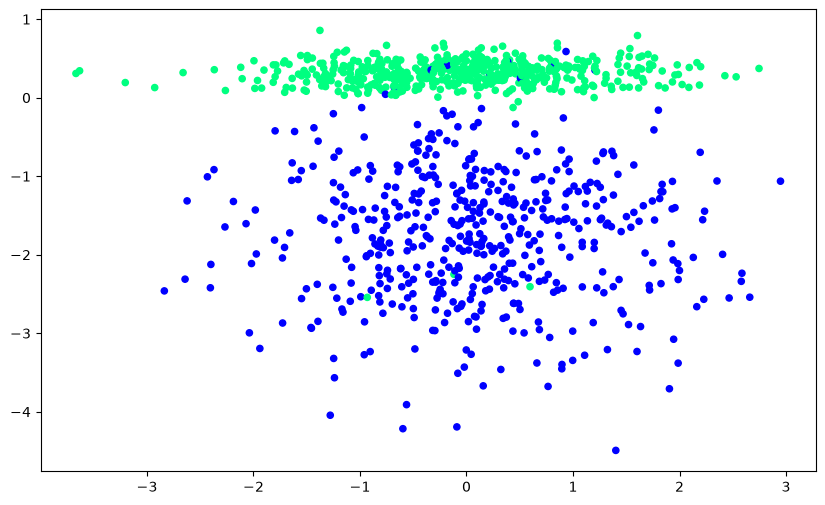

In [63]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0], X[:,1],c=y,cmap="winter",s=20)

In [64]:
def perceptron(X, y):
    w1=w2=b= 1
    
    for _ in range(epoch):
        for i in range(X.shape[0]):
            z = w1*X[i][0] + w2*X[i][1] + b  # w1*Xi1 + w2*Xi2 + b
            
            if z*y[i]<0:
                w1 = w1 - (lr * (-y[i]* X[i][0]))
                w2 = w2 - (lr * (-y[i] * X[i][1]))
                b = b - (lr * (-y[i]))
    
    return b, w1, w2
                

In [65]:
b,w1,w2= perceptron(X,y)

In [66]:
print(b)
print(w1, w2)

-7.528699885739343e-16
0.0022333945134155233 0.04781139662706251


In [67]:
m = -(w1/w2)
c = -(b/w2)

print(m,c)

-0.046712597225226485 1.574666380165498e-14


(-3.0, 2.0)

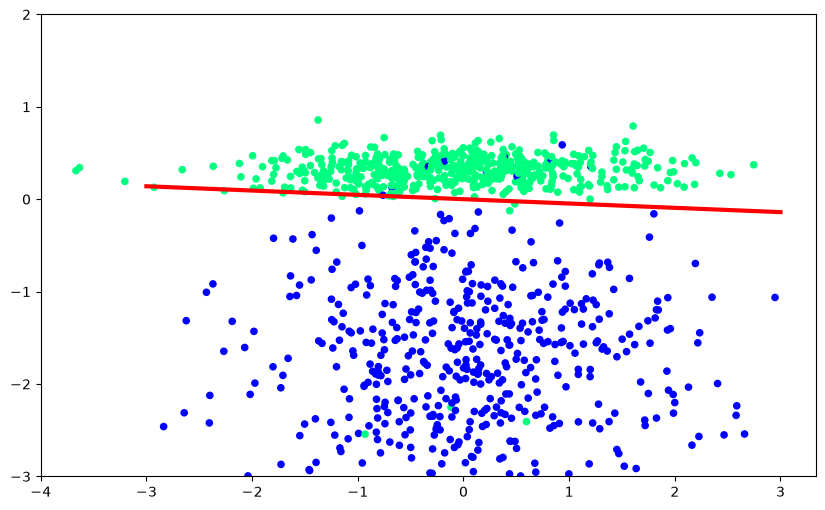

In [68]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + c

plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=20)
plt.ylim(-3,2)